# Lab 1: Data visualization with Matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NgKhiem69/datascience_course/blob/main/labs/01-working-with-data/visualization-with-matplotlib.ipynb)

**Nội dung:** biểu đồ cột/histogram (phổ điểm), nhiều biểu đồ trên một hình (subplots), biểu đồ đường (giá vàng theo thời gian) và biểu đồ phân tán (scatter).

## 0. Thiết lập môi trường (Google Colab)

Dữ liệu được đọc trực tiếp từ thư mục `data/` của repo GitHub qua đường dẫn *raw*, nên không cần upload file hay mount Google Drive.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Đường dẫn raw tới thư mục data trên GitHub
GITHUB_USER, GITHUB_REPO, BRANCH = "NgKhiem69", "datascience_course", "main"
DATA_URL = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/data"

def data_path(filename):
    """Trả về URL raw của một file trong thư mục data/ của repo."""
    return f"{DATA_URL}/{filename}"

# Kiểm tra đang chạy trên Colab hay máy local
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running on Colab:", IN_COLAB)
print("Data URL:", DATA_URL)

Running on Colab: False
Data URL: https://raw.githubusercontent.com/NgKhiem69/datascience_course/main/data


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Thư mục lưu hình
FIG_DIR = "figs"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Bar plot / Histogram — phổ điểm thi

### 1.1 Chuẩn bị dữ liệu

In [3]:
# Đọc dữ liệu điểm thi
grade_df = pd.read_excel(data_path("final_grades.xlsx"))

# Nhóm ngành IT / Non-IT
it_majors = ["khmt", "cntt", "ttql"]
grade_df["MajorGroup"] = grade_df["Major"].apply(lambda x: "IT" if x in it_majors else "Non-IT")
grade_df.head()

,Major,Grade,MajorGroup
0,cdt,8.21,Non-IT
1,cdt,9.25,Non-IT
2,cdt,8.50,Non-IT
3,cdt,3.90,Non-IT
4,cdt,7.50,Non-IT


In [4]:
def grade_stats(grades):
    """Tính các thống kê cơ bản của một dãy điểm."""
    return {
        "Số bài thi": len(grades),
        "Điểm trung bình": grades.mean(),
        "Điểm trung vị": grades.median(),
        "Độ lệch chuẩn": grades.std(),
        "Điểm thấp nhất": grades.min(),
        "Điểm cao nhất": grades.max(),
    }

stats_all = grade_stats(grade_df["Grade"])
for k, v in stats_all.items():
    print(f"{k}: {v:.2f}" if isinstance(v, float) else f"{k}: {v}")

Số bài thi: 1230
Điểm trung bình: 6.24
Điểm trung vị: 6.23
Độ lệch chuẩn: 1.61
Điểm thấp nhất: 2.29
Điểm cao nhất: 10.00


In [5]:
# Các khoảng điểm (bins) cách nhau 0.5
bins = np.arange(0, 10.5, 0.5)
print(bins)

[ 0.   0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5
  7.   7.5  8.   8.5  9.   9.5 10. ]


### 1.2 Phổ điểm toàn bộ sinh viên

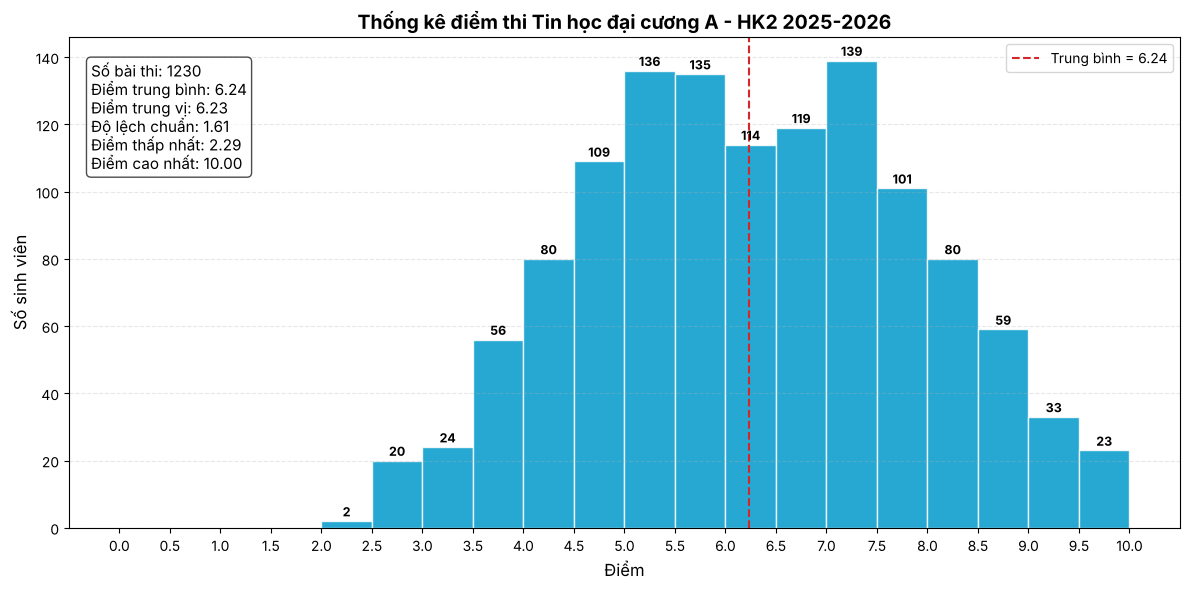

In [6]:
plt.figure(figsize=(12, 6))

counts, edges, patches = plt.hist(
    grade_df["Grade"],
    bins=bins,
    color="#0099cc",
    edgecolor="white",
    alpha=0.85,
)

# Ghi số sinh viên lên đầu mỗi cột
for count, left, right in zip(counts, edges[:-1], edges[1:]):
    if count > 0:
        plt.text((left + right) / 2, count + 0.5, str(int(count)),
                 ha="center", va="bottom", fontsize=9, fontweight="bold")

# Hộp thống kê ở góc trên bên trái
stats_text = "\n".join(
    f"{k}: {v:.2f}" if isinstance(v, float) else f"{k}: {v}" for k, v in stats_all.items()
)
plt.gca().text(0.02, 0.95, stats_text, transform=plt.gca().transAxes,
               fontsize=11, va="top", ha="left",
               bbox=dict(boxstyle="round", facecolor="white", alpha=0.7))

# Đường thẳng đứng đánh dấu điểm trung bình
plt.axvline(stats_all["Điểm trung bình"], color="#d62728", linestyle="--", linewidth=1.5,
            label=f"Trung bình = {stats_all['Điểm trung bình']:.2f}")

plt.title("Thống kê điểm thi Tin học đại cương A - HK2 2025-2026", fontsize=14, weight="bold")
plt.xlabel("Điểm", fontsize=12)
plt.ylabel("Số sinh viên", fontsize=12)
plt.xticks(bins)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/THDC-Grade-Stats.png", dpi=150)
plt.show()

### 1.3 Stacked histogram — so sánh nhóm ngành CNTT với các ngành khác

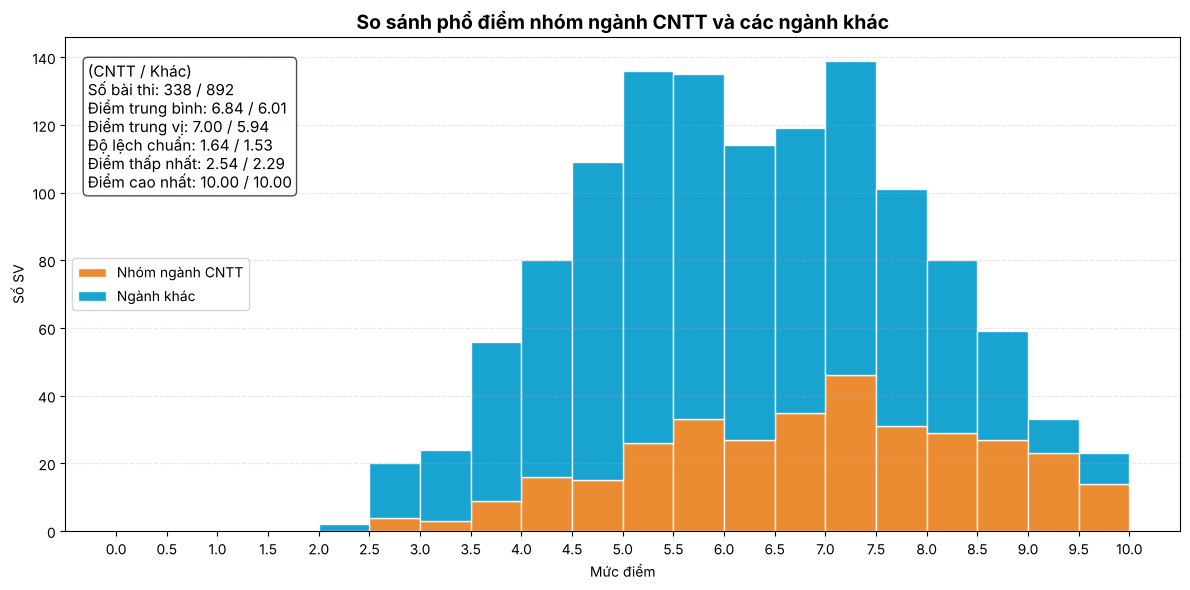

In [7]:
grades_it = grade_df.loc[grade_df["MajorGroup"] == "IT", "Grade"]
grades_others = grade_df.loc[grade_df["MajorGroup"] == "Non-IT", "Grade"]

plt.figure(figsize=(12, 6))
plt.hist([grades_it, grades_others], bins=bins, stacked=True, alpha=0.9,
         label=["Nhóm ngành CNTT", "Ngành khác"],
         color=["#ea801c", "#0099cc"], edgecolor="white")

s_it, s_ot = grade_stats(grades_it), grade_stats(grades_others)
lines = ["(CNTT / Khác)"]
for k in s_it:
    a, b = s_it[k], s_ot[k]
    lines.append(f"{k}: {a:.2f} / {b:.2f}" if isinstance(a, float) else f"{k}: {a} / {b}")
plt.gca().text(0.02, 0.95, "\n".join(lines), transform=plt.gca().transAxes,
               fontsize=11, va="top", ha="left",
               bbox=dict(boxstyle="round", facecolor="white", alpha=0.7))

plt.xlabel("Mức điểm")
plt.ylabel("Số SV")
plt.title("So sánh phổ điểm nhóm ngành CNTT và các ngành khác", fontsize=14, weight="bold")
plt.xticks(bins)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(loc="center left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/grade-by-major.pdf")
plt.show()

### 1.4 Bar chart — điểm trung bình và tỉ lệ đạt theo ngành

Chỉ xét các ngành có từ 30 sinh viên trở lên.

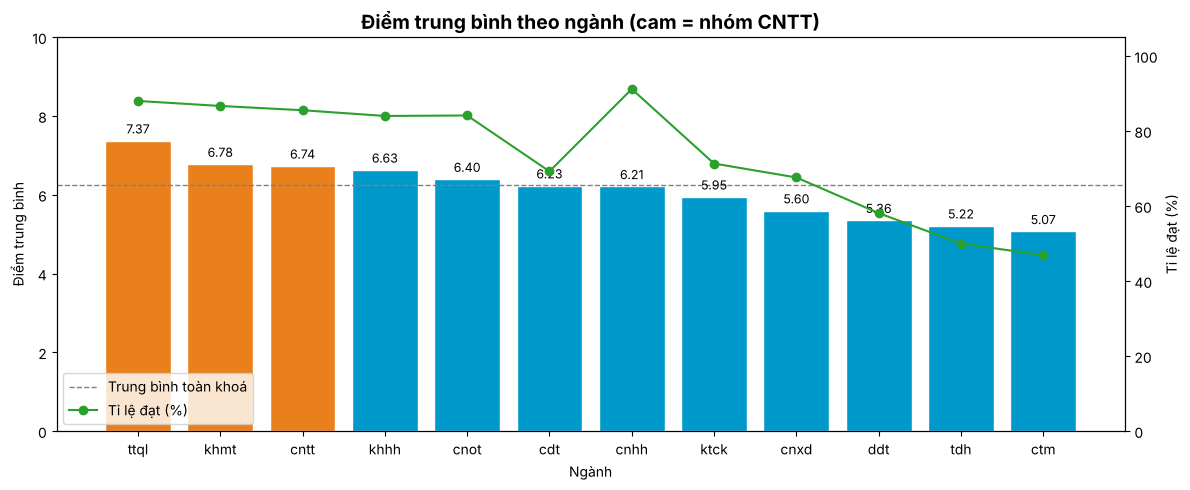

In [8]:
major_stats = (
    grade_df.groupby("Major")["Grade"]
    .agg(students="count", mean="mean", pass_rate=lambda g: (g >= 5).mean() * 100)
)
major_stats = major_stats[major_stats["students"] >= 30].sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
colors = ["#ea801c" if m in it_majors else "#0099cc" for m in major_stats.index]
bars = ax.bar(major_stats.index, major_stats["mean"], color=colors, edgecolor="white")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.axhline(grade_df["Grade"].mean(), color="gray", linestyle="--", linewidth=1,
           label="Trung bình toàn khoá")

# Trục phụ hiển thị tỉ lệ đạt
ax2 = ax.twinx()
ax2.plot(major_stats.index, major_stats["pass_rate"], color="#2ca02c", marker="o", label="Tỉ lệ đạt (%)")
ax2.set_ylim(0, 105)
ax2.set_ylabel("Tỉ lệ đạt (%)")

ax.set_title("Điểm trung bình theo ngành (cam = nhóm CNTT)", fontsize=14, weight="bold")
ax.set_xlabel("Ngành")
ax.set_ylabel("Điểm trung bình")
ax.set_ylim(0, 10)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower left")
plt.tight_layout()
plt.show()

### 1.5 Box plot — phân tán điểm theo nhóm ngành

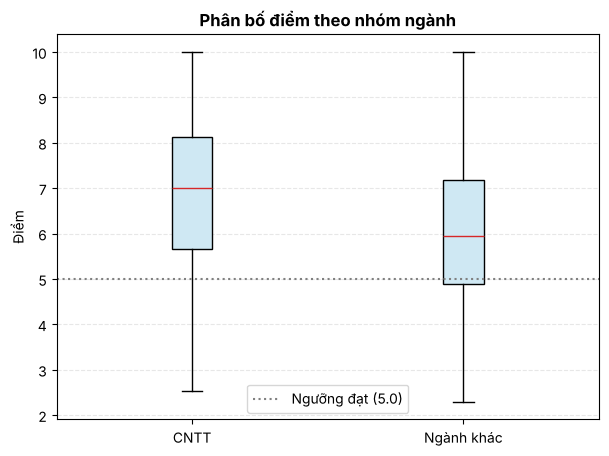

In [9]:
plt.figure(figsize=(7, 5))
plt.boxplot([grades_it, grades_others], tick_labels=["CNTT", "Ngành khác"], patch_artist=True,
            boxprops=dict(facecolor="#cfe8f3"), medianprops=dict(color="#d62728"))
plt.axhline(5, color="gray", linestyle=":", label="Ngưỡng đạt (5.0)")
plt.ylabel("Điểm")
plt.title("Phân bố điểm theo nhóm ngành", weight="bold")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()

## 2. Multiple plots (subplots)

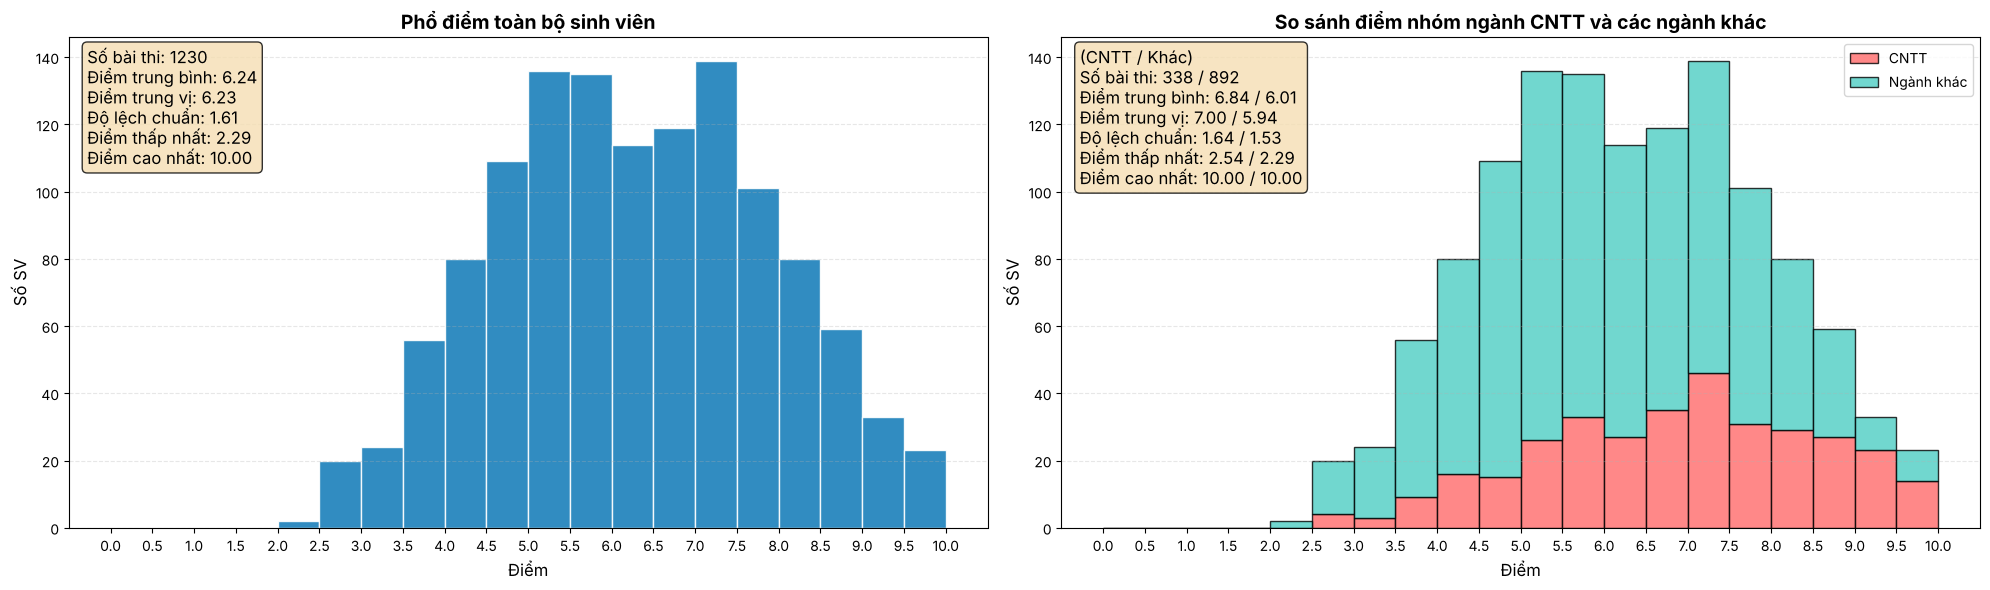

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

# Biểu đồ 1: phổ điểm toàn bộ sinh viên
axes[0].hist(grade_df["Grade"], bins=bins, edgecolor="white", alpha=0.9, color="#1a80bb")
axes[0].set_title("Phổ điểm toàn bộ sinh viên", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Điểm", fontsize=12)
axes[0].set_ylabel("Số SV", fontsize=12)
axes[0].set_xticks(bins)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
text1 = "\n".join(f"{k}: {v:.2f}" if isinstance(v, float) else f"{k}: {v}" for k, v in stats_all.items())
axes[0].text(0.02, 0.98, text1, transform=axes[0].transAxes, va="top", fontsize=12,
             bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))

# Biểu đồ 2: stacked histogram CNTT vs ngành khác
axes[1].hist([grades_it, grades_others], bins=bins, stacked=True,
             label=["CNTT", "Ngành khác"], color=["#FF6B6B", "#4ECDC4"],
             edgecolor="black", alpha=0.8)
axes[1].set_title("So sánh điểm nhóm ngành CNTT và các ngành khác", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Điểm", fontsize=12)
axes[1].set_ylabel("Số SV", fontsize=12)
axes[1].legend(loc="upper right")
axes[1].set_xticks(bins)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
text2 = "\n".join(lines)
axes[1].text(0.02, 0.98, text2, transform=axes[1].transAxes, va="top", fontsize=12,
             bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/final-stats.pdf")
plt.show()

## 3. Line plot — giá vàng theo thời gian

Nguồn dữ liệu: [datahub.io/core/gold-prices](https://datahub.io/core/gold-prices) (giá vàng trung bình tháng, USD/ounce).

In [11]:
gold_df = pd.read_csv(data_path("gold_price_monthly.csv"))
# Chuyển cột Date (dạng YYYY-MM) sang kiểu datetime và đặt làm index
gold_df["Date"] = pd.to_datetime(gold_df["Date"], format="%Y-%m")
gold_df = gold_df.set_index("Date").sort_index()

print("Khoảng thời gian:", gold_df.index.min().date(), "→", gold_df.index.max().date())
print("Số tháng:", len(gold_df))
gold_df.describe()

Khoảng thời gian: 1833-01-01 → 2026-08-01
Số tháng: 2324


,Price
count,2324.000000
mean,243.193163
std,552.061003
min,17.060000
25%,18.940000
50%,20.680000
75%,182.500000
max,5020.000000


### 3.1 Toàn bộ chuỗi thời gian (thang tuyến tính và thang log)

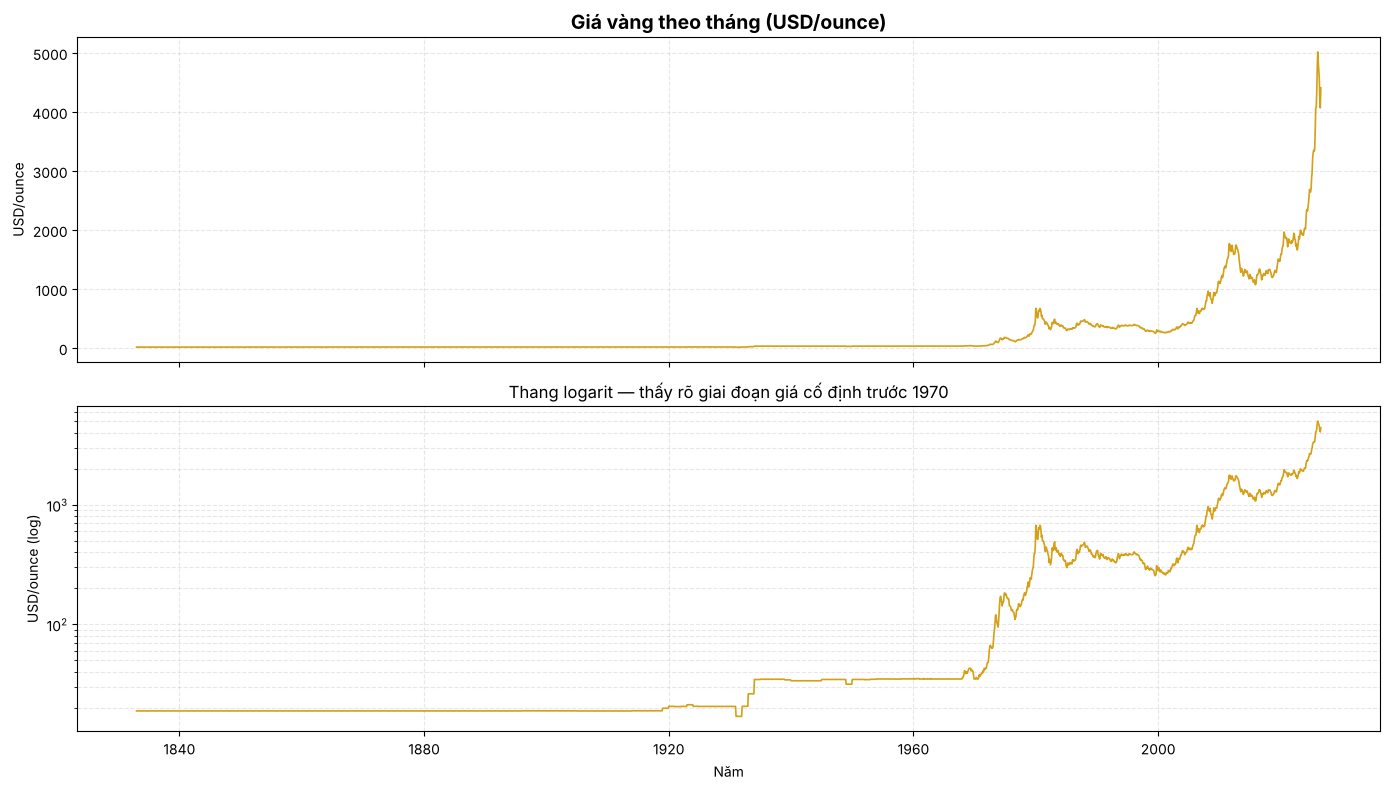

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(gold_df.index, gold_df["Price"], color="#d4a017", linewidth=1.2)
axes[0].set_title("Giá vàng theo tháng (USD/ounce)", fontsize=14, weight="bold")
axes[0].set_ylabel("USD/ounce")
axes[0].grid(linestyle="--", alpha=0.3)

axes[1].plot(gold_df.index, gold_df["Price"], color="#d4a017", linewidth=1.2)
axes[1].set_yscale("log")
axes[1].set_title("Thang logarit — thấy rõ giai đoạn giá cố định trước 1970", fontsize=12)
axes[1].set_ylabel("USD/ounce (log)")
axes[1].set_xlabel("Năm")
axes[1].grid(linestyle="--", alpha=0.3, which="both")

plt.tight_layout()
plt.show()

### 3.2 Giai đoạn từ năm 2000 với đường trung bình trượt (moving average)

Trung bình trượt 12 tháng giúp làm mượt dao động ngắn hạn để thấy rõ xu hướng.

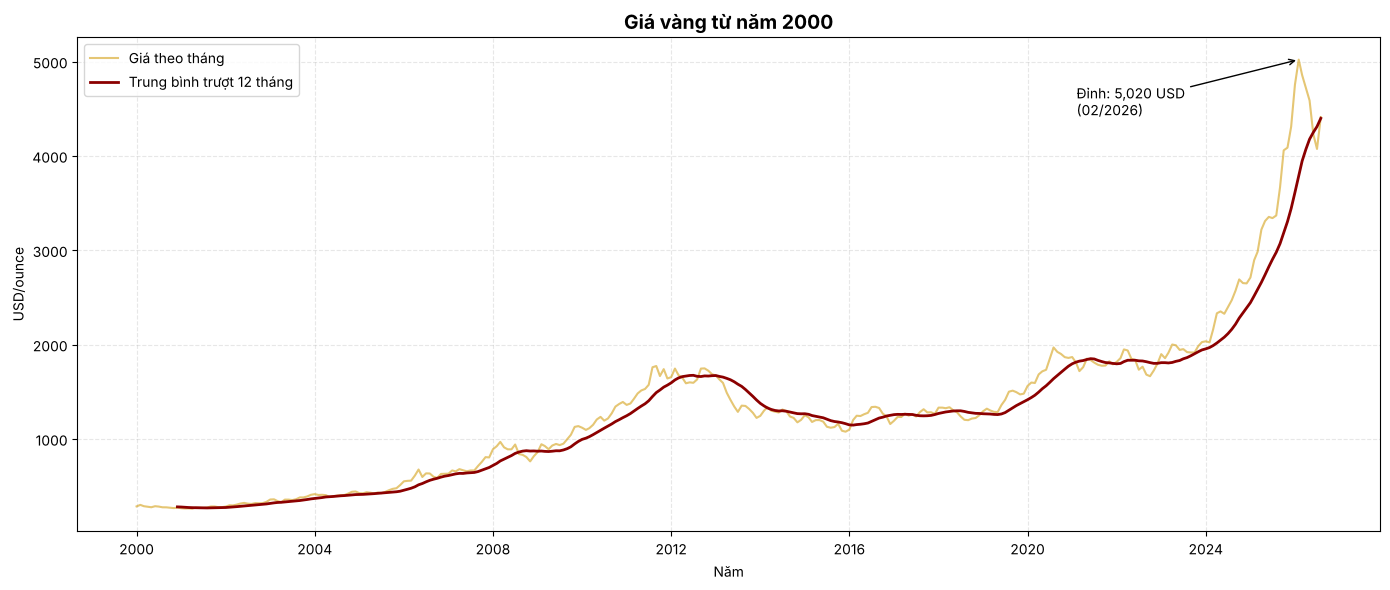

In [13]:
recent = gold_df.loc["2000":].copy()
recent["MA12"] = recent["Price"].rolling(window=12).mean()

peak_date = recent["Price"].idxmax()
peak_price = recent["Price"].max()

plt.figure(figsize=(14, 6))
plt.plot(recent.index, recent["Price"], label="Giá theo tháng", color="#d4a017", alpha=0.6)
plt.plot(recent.index, recent["MA12"], label="Trung bình trượt 12 tháng", color="#8b0000", linewidth=2)
plt.annotate(f"Đỉnh: {peak_price:,.0f} USD\n({peak_date:%m/%Y})",
             xy=(peak_date, peak_price), xytext=(-160, -40), textcoords="offset points",
             arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)
plt.title("Giá vàng từ năm 2000", fontsize=14, weight="bold")
plt.xlabel("Năm")
plt.ylabel("USD/ounce")
plt.legend()
plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.3 Tăng trưởng giá theo năm

Gom dữ liệu theo năm (`resample`) và tính % thay đổi so với năm trước.

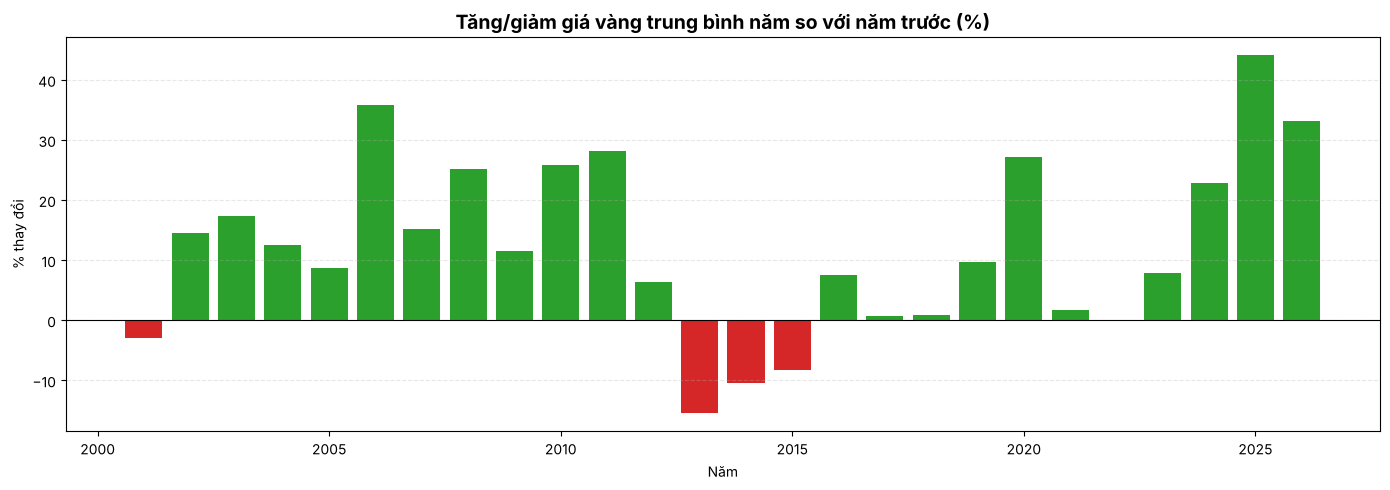

In [14]:
yearly = gold_df["Price"].resample("YE").mean().loc["2000":]
yoy = yearly.pct_change().mul(100).dropna()

plt.figure(figsize=(14, 5))
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in yoy]
plt.bar(yoy.index.year, yoy.values, color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Tăng/giảm giá vàng trung bình năm so với năm trước (%)", fontsize=14, weight="bold")
plt.xlabel("Năm")
plt.ylabel("% thay đổi")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Scatter plot

### Ví dụ 1: Quan hệ giữa số giờ học và điểm thi (`studyhours.csv`)

In [15]:
studyhours_df = pd.read_csv(data_path("studyhours.csv"))
studyhours_df.head()

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


In [16]:
studyhours_df.describe()

,Study Hours,Exam Score
count,33.000000,33.000000
mean,15.772727,74.612121
std,7.608723,18.711206
min,3.000000,40.000000
25%,9.600000,58.500000
50%,17.400000,78.800000
75%,21.300000,90.800000
max,30.000000,100.000000


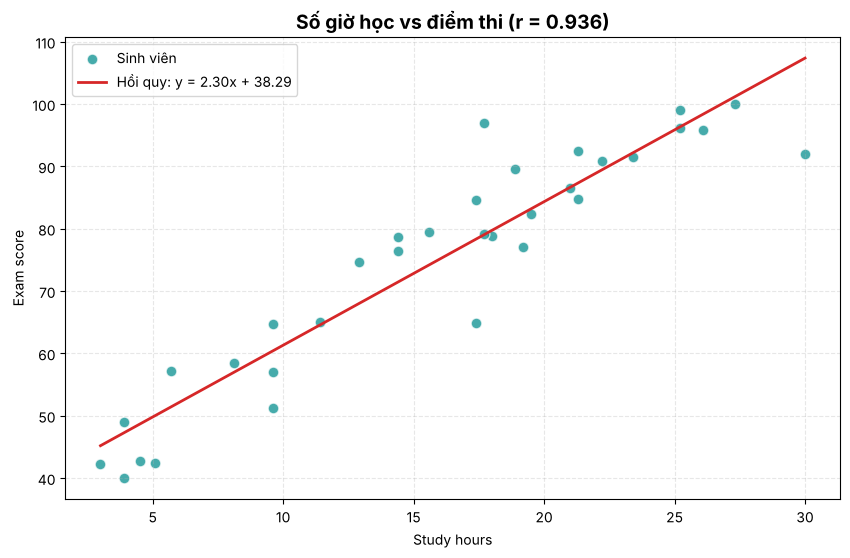

Hệ số tương quan r = 0.936 → tương quan thuận mạnh: học nhiều giờ hơn thì điểm thường cao hơn.


In [17]:
study_hours = studyhours_df["Study Hours"]
exam_score = studyhours_df["Exam Score"]

# Hệ số tương quan Pearson
r = study_hours.corr(exam_score)

# Đường hồi quy tuyến tính y = a*x + b bằng np.polyfit
a, b = np.polyfit(study_hours, exam_score, deg=1)
x_line = np.linspace(study_hours.min(), study_hours.max(), 100)

plt.figure(figsize=(10, 6))
plt.scatter(study_hours, exam_score, alpha=0.75, color="#088F8F", s=60,
            edgecolor="white", label="Sinh viên")
plt.plot(x_line, a * x_line + b, color="#d62728", linewidth=2,
         label=f"Hồi quy: y = {a:.2f}x + {b:.2f}")
plt.title(f"Số giờ học vs điểm thi (r = {r:.3f})", fontsize=14, weight="bold")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.legend()
plt.grid(linestyle="--", alpha=0.3)
plt.show()

print(f"Hệ số tương quan r = {r:.3f} → tương quan thuận mạnh: học nhiều giờ hơn thì điểm thường cao hơn.")

### Ví dụ 2: Bộ dữ liệu Iris

In [18]:
import sklearn.datasets as datasets

iris = datasets.load_iris()
print("Iris dataset statistics:")
print(f"Number of samples: {iris.data.shape[0]}")
print(f"Number of features: {iris.data.shape[1]}")
print(f"Feature names: {iris.feature_names}")
print(f"Target names: {list(iris.target_names)}")

Iris dataset statistics:
Number of samples: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


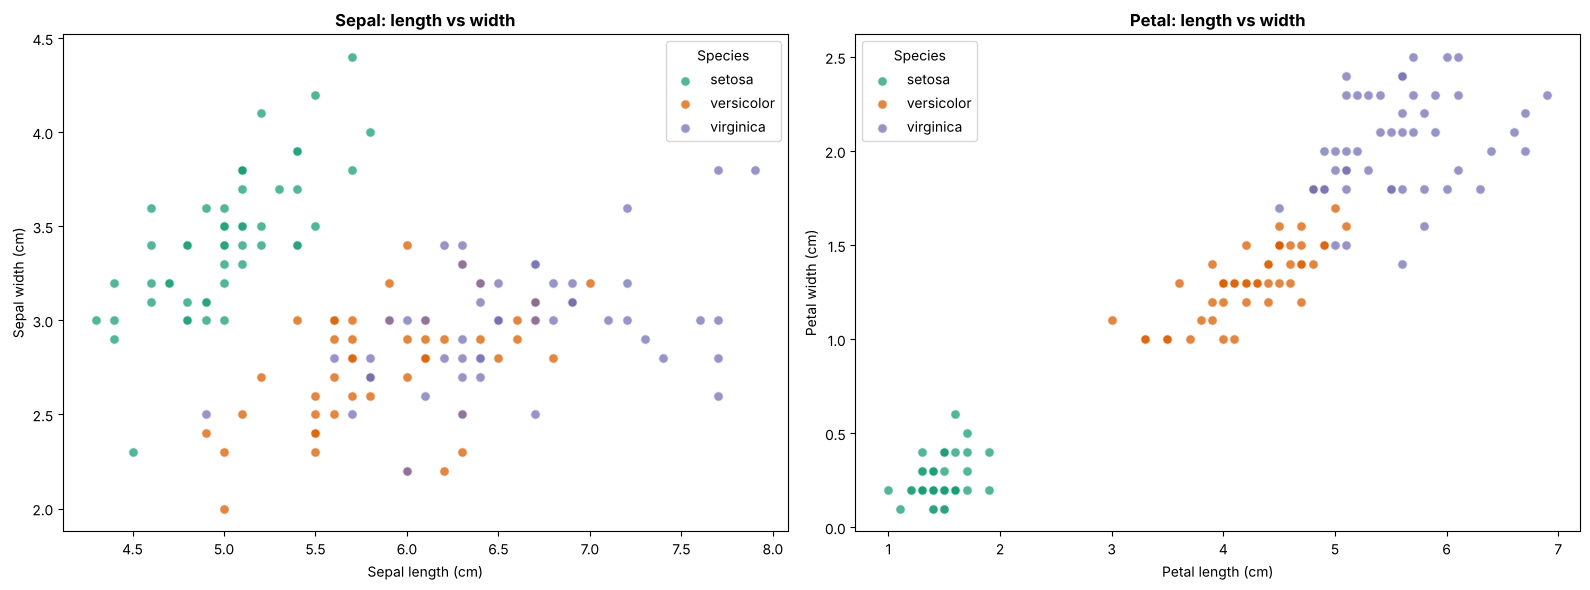

In [19]:
species = iris.target
names = [str(n) for n in iris.target_names]
colors = ["#1b9e77", "#d95f02", "#7570b3"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Sepal length vs sepal width
for i, name in enumerate(names):
    mask = species == i
    axes[0].scatter(iris.data[mask, 0], iris.data[mask, 1], color=colors[i],
                    alpha=0.75, label=name, edgecolor="white", s=50)
axes[0].set_xlabel("Sepal length (cm)")
axes[0].set_ylabel("Sepal width (cm)")
axes[0].set_title("Sepal: length vs width", weight="bold")
axes[0].legend(title="Species")

# Petal length vs petal width
for i, name in enumerate(names):
    mask = species == i
    axes[1].scatter(iris.data[mask, 2], iris.data[mask, 3], color=colors[i],
                    alpha=0.75, label=name, edgecolor="white", s=50)
axes[1].set_xlabel("Petal length (cm)")
axes[1].set_ylabel("Petal width (cm)")
axes[1].set_title("Petal: length vs width", weight="bold")
axes[1].legend(title="Species")

plt.tight_layout()
plt.show()

Nhận xét: theo cặp đặc trưng **petal** (cánh hoa), ba loài tách biệt rõ hơn nhiều so với cặp **sepal** (đài hoa) — *setosa* tách hẳn, *versicolor* và *virginica* chỉ chồng lấn một ít.

### Ví dụ 3: Scatter matrix — xem tất cả các cặp đặc trưng

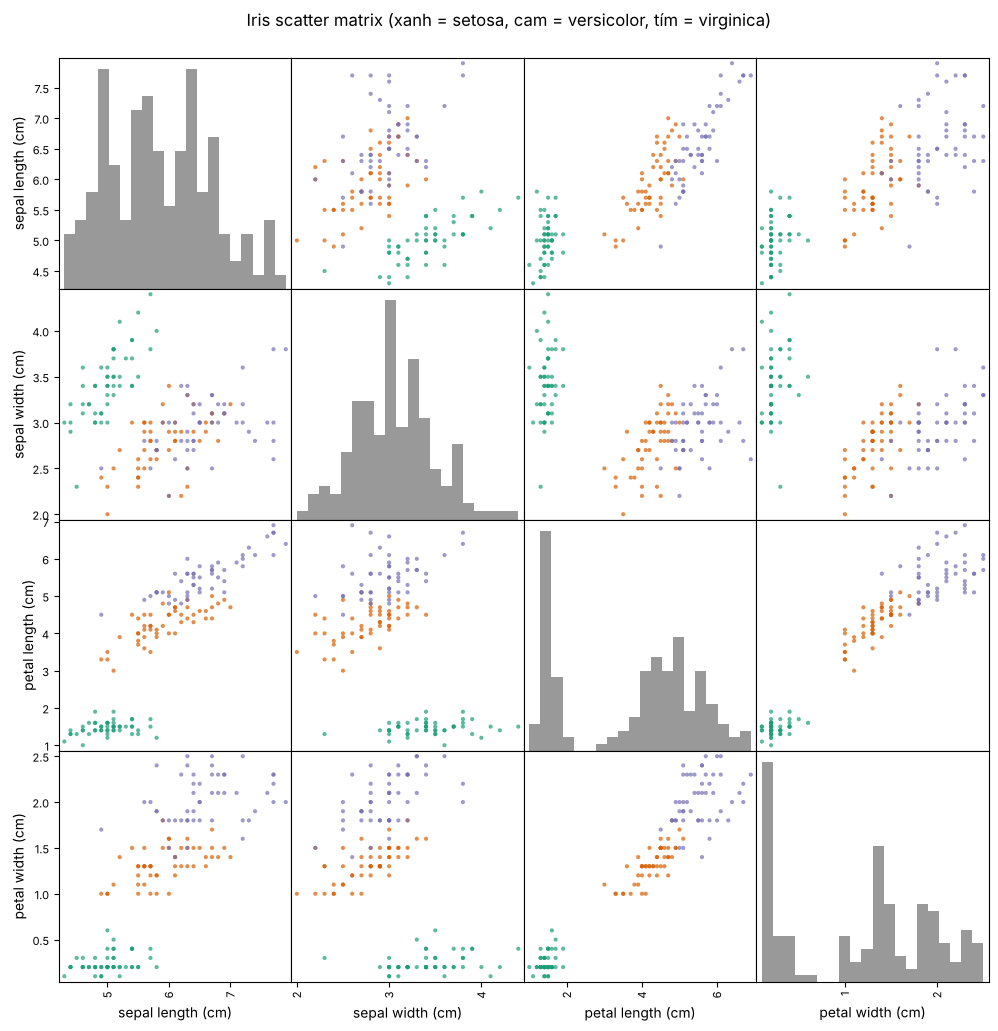

In [20]:
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
point_colors = [colors[i] for i in species]
pd.plotting.scatter_matrix(iris_df, c=point_colors, figsize=(12, 12), alpha=0.7,
                           diagonal="hist", hist_kwds={"color": "#999999", "bins": 20})
plt.suptitle("Iris scatter matrix (xanh = setosa, cam = versicolor, tím = virginica)", y=0.92)
plt.show()

## 5. Tải các hình đã lưu (Colab)

In [21]:
print(os.listdir(FIG_DIR))
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("figs", "zip", FIG_DIR)
    files.download("figs.zip")

['final-stats.pdf', 'grade-by-major.pdf', 'THDC-Grade-Stats.png']
